# RSM 01 · Optimising batch esterification yield

**Chemical Engineering Modelling Labs · Worked teaching edition**

**Introductory case · three independent inputs.** Learn design coding, interaction effects, response curvature, uncertainty and confirmation of a local optimum.

## Start here · use in Google Colab
Open this `.ipynb` with **File → Upload notebook**, keep a **CPU runtime**, and use **Runtime → Run all**. Save an individual copy before editing. All data are generated inside the notebook; the core exercise needs no upload, process simulator, API key, GPU or Julia installation.

Every executable line has an adjacent English comment. Markdown between cells explains the scientific purpose and the result to inspect. Saved tables and plots are retained in this worked edition so that it is also readable without running it.

**Teaching contract.** These are synthetic observations, not laboratory measurements. Ground truth is disclosed for teaching and independent audits; model fitting uses noisy training targets only. Validation selects a model; test and challenge sets report performance after selection. Repeatedly redesigning a model after reading test errors invalidates the original test.

**Follow the sequence:** context → data → model structure → fitting → validation → test diagnostics → engineering interpretation → exercises → export.

## 1. Set up Python

In [1]:
import importlib.util  # Check the runtime before installing any packages.
import subprocess  # Run pip through this notebook's Python interpreter when required.
import sys  # Identify the active interpreter and record its version.
requirements = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'scipy': 'scipy', 'statsmodels': 'statsmodels', 'sklearn': 'scikit-learn', 'sympy': 'sympy'}  # Map Python imports to package names.
missing = [package for module, package in requirements.items() if importlib.util.find_spec(module) is None]  # Find only the dependencies that are absent.
if missing:  # Keep a working Colab environment unchanged whenever possible.
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])  # Install missing packages in the current runtime.
import numpy as np  # Perform numerical array calculations and generate controlled random noise.
import pandas as pd  # Display labelled datasets and result tables.
import matplotlib.pyplot as plt  # Create figures with the default Matplotlib colours.
import scipy  # Record the numerical-library version for reproducibility.
from scipy import stats  # Obtain statistical distributions and diagnostics.
from scipy.optimize import minimize, least_squares  # Optimise operating points and fit nonlinear equation parameters.
import statsmodels.api as sm  # Fit linear-in-coefficient regressions and estimate statistical intervals.
from sklearn.preprocessing import PolynomialFeatures  # Generate polynomial terms for the RSM baselines.
from itertools import combinations, product  # Enumerate experimental-design pairs and symbolic candidate structures.
from pathlib import Path  # Manage output files independently of the operating system.
import json  # Save fitted-model specifications in readable form.
import shutil  # Bundle figures and tables into a downloadable archive.
from IPython.display import display, Markdown, Math, FileLink  # Embed formatted tables, equations and links in the notebook.
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'figure.dpi': 110})  # Keep figure text legible without changing colour or plot style.
pd.set_option('display.max_columns', 16)  # Keep the important columns visible in result tables.
versions = pd.DataFrame({'component': ['Python', 'NumPy', 'pandas', 'SciPy', 'statsmodels'], 'version': [sys.version.split()[0], np.__version__, pd.__version__, scipy.__version__, sm.__version__]})  # Record the environment used for this execution.
display(versions)  # Show the software versions before modelling begins.

,component,version
0,Python,3.13.5
1,NumPy,2.3.5
2,pandas,2.2.3
3,SciPy,1.17.0
4,statsmodels,0.14.6


**Checkpoint.** The version table should appear without an exception. Core dependencies are installed only when absent. Minor numerical differences between package versions are possible.

In [2]:
SEED = 20261010  # Reproduce the original four-case teaching dataset package.
case_seed = np.random.SeedSequence(SEED).spawn(4)[0]  # Select an independent random stream for this chemical-engineering case.
design_seed, noise_seed = case_seed.spawn(2)  # Keep operating-point sampling separate from observation noise.
rng_design = np.random.default_rng(design_seed)  # Generate reproducible experimental conditions.
rng_noise = np.random.default_rng(noise_seed)  # Generate reproducible but independent measurement errors.
RESULTS = Path('results_01_rsm_esterification')  # Store this case's figures, data and fitted-model files in one place.
RESULTS.mkdir(exist_ok=True)  # Reuse the same folder safely when the notebook is rerun.
print('Output folder:', RESULTS.resolve())  # Identify the files that can be downloaded at the end.

Output folder: /mnt/data/Colab_Teaching_Notebooks/results_01_rsm_esterification


**Reproducibility.** The default settings regenerate the corresponding observations in the earlier dataset package. Changing the seed represents a new synthetic experiment; do not choose a seed for favourable performance.

In [3]:
def lhs(n, bounds, rng):  # Spread observations across each input range using Latin hypercube sampling.
    bounds = np.asarray(bounds, dtype=float)  # Convert the physical lower and upper limits into an array.
    u = np.column_stack([(rng.permutation(n) + rng.random(n)) / n for _ in bounds])  # Sample every stratum once in each input direction.
    return bounds[:, 0] + u * (bounds[:, 1] - bounds[:, 0])  # Map the samples into the physical operating box.

def save_plot(fig, filename):  # Display and preserve each result figure.
    fig.tight_layout()  # Reduce crowding between labels, axes and titles.
    fig.savefig(RESULTS / (filename + '.png'), dpi=160, bbox_inches='tight')  # Save a high-resolution copy for teaching slides or reports.
    plt.show()  # Embed the figure in the notebook output.
    plt.close(fig)  # Release figure memory before continuing to the next plot.

def metrics(y, prediction):  # Quantify predictions without refitting the model.
    y, prediction = np.asarray(y), np.asarray(prediction)  # Ensure compatible numerical arrays.
    errors = prediction - y  # Define a positive error as an overprediction.
    return {'RMSE': float(np.sqrt(np.mean(errors**2))), 'MAE': float(np.mean(np.abs(errors))), 'R_squared': float(1 - np.sum(errors**2) / np.sum((y-y.mean())**2))}  # Return error magnitudes and the mean-response comparison.

def parity(y, prediction, title, units, filename):  # Compare new observations with fixed-model predictions.
    fig, ax = plt.subplots(figsize=(6.8, 5.2))  # Create a single readable plotting panel.
    ax.scatter(y, prediction, s=26, alpha=0.7)  # Draw one marker per independent evaluation observation.
    limits = [min(np.min(y), np.min(prediction)), max(np.max(y), np.max(prediction))]  # Cover observed and predicted values with the same numerical range.
    ax.plot(limits, limits, '--', label='Perfect prediction')  # Mark the identity line as the reference.
    ax.set(xlabel='Observed '+units, ylabel='Predicted '+units, title=title)  # State the response units and evaluation purpose.
    ax.legend()  # Identify the reference line without cluttering the plot.
    save_plot(fig, filename)  # Save and embed this parity figure.

**Read the helpers.** RMSE and MAE retain the response units. $R^2$ can be negative. A scatter plot is an evaluation tool, not proof of a valid mechanism.

## 2. The chemical-engineering question
Which temperature, alcohol-to-acid ratio and catalyst loading maximise **isolated ester yield after 90 minutes**? Assume a well-mixed batch reactor and conditions maintaining a liquid reacting mixture.

| Input | Range | Centre |
|---|---:|---:|
| Temperature, $T$ | 55–75 °C | 65 °C |
| Alcohol-to-acid molar ratio, $M$ | 1.5–4.5 | 3.0 |
| Catalyst loading relative to initial acid, $w$ | 0.5–1.5 mass % | 1.0 mass % |

This is a deliberately **local, invented process-performance surface**, not a universal kinetic or equilibrium model. The hidden response is quadratic so that the first lesson has an appropriate model family:

$$x_1=(T-65)/10,\qquad x_2=(M-3)/1.5,\qquad x_3=(w-1)/0.5.$$
$$Y=88+4x_1+3x_2+2x_3-5x_1^2-4x_2^2-3x_3^2+2x_1x_2-1.5x_1x_3+x_2x_3.$$
$$Y_{\mathrm{obs}}=Y+\varepsilon,\qquad \varepsilon\sim\mathcal N(0,1^2).$$

The noise standard deviation is **one percentage point**, not one per cent relative noise. In a discovery exercise, hide this generator until students have inspected the observed responses.

In [4]:
FEATURES = ['temperature_C', 'alcohol_acid_molar_ratio', 'catalyst_mass_percent']  # State the three independent inputs and their units.
BOUNDS = np.array([[55, 75], [1.5, 4.5], [0.5, 1.5]], dtype=float)  # Define the local operating range for each input.
CENTRE = BOUNDS.mean(axis=1)  # Calculate the midpoint of each physical range.
HALF_RANGE = np.diff(BOUNDS, axis=1).ravel()/2  # Set the scale used to code each factor.
NOISE_SD = 1.0  # Choose one percentage point of independent measurement scatter.
def truth(x):  # Define the instructor's synthetic process, not a learned model.
    a, c, d = ((np.atleast_2d(x)-CENTRE)/HALF_RANGE).T  # Convert the physical inputs into three coded variables.
    return 88+4*a+3*c+2*d-5*a*a-4*c*c-3*d*d+2*a*c-1.5*a*d+c*d  # Evaluate the assumed yield surface.
print('Noise-free centre yield:', truth(CENTRE)[0], '%')  # Verify the zero-coded-input reference value.

Noise-free centre yield: 88.0 %


**Checkpoint.** The centre gives 88% noise-free yield. The squared terms create curvature; the cross-products make the effect of one variable depend on another.

In [5]:
def box_behnken(k, centres, rng):  # Construct only the three- and four-factor designs used in these lessons.
    if k not in (3, 4) or centres < 2:  # Reject unsupported designs and insufficient repeat observations.
        raise ValueError('Use three or four factors and at least two centre runs.')  # Explain the supported teaching configuration.
    rows = []  # Accumulate coded experimental conditions.
    for i, j in combinations(range(k), 2):  # Activate each pair of factors in turn.
        for signs in product((-1.0, 1.0), repeat=2):  # Visit each low/high combination of that pair.
            row = np.zeros(k)  # Hold the other factors at their centre levels.
            row[[i, j]] = signs  # Set the two active factors to their coded extremes.
            rows.append(row)  # Store the new experimental setting.
    rows.extend([np.zeros(k) for _ in range(centres)])  # Add independent centre replicates to estimate repeatability.
    rows = np.asarray(rows)  # Represent the design as one row per experimental run.
    return rows[rng.permutation(len(rows))]  # Randomise run order to avoid a systematic factor sequence.

**Design logic.** The three-factor Box–Behnken design has 12 non-centre runs and five independent centre replicates. Keep all 17 for fitting; generate separate validation and test observations.

In [6]:
frames = []  # Collect the independently generated data partitions.
for split, n in [('train', 17), ('validation', 12), ('test', 100)]:  # Fix the evaluation budgets before examining model performance.
    x = CENTRE+box_behnken(3, 5, rng_design)*HALF_RANGE if split == 'train' else lhs(n, BOUNDS, rng_design)  # Use BBD for fitting and LHS for held-out evaluation.
    clean = truth(x)  # Store the disclosed noise-free reference only for teaching audits.
    observed = clean+rng_noise.normal(0, NOISE_SD, n)  # Simulate independent observed yields.
    frame = pd.DataFrame(x, columns=FEATURES)  # Label the operating conditions in physical units.
    frame['yield_observed_pct'], frame['yield_true_pct'], frame['split'] = observed, clean, split  # Separate the observed target from the instructor's truth.
    frames.append(frame)  # Preserve this data partition.
data = pd.concat(frames, ignore_index=True)  # Assemble the complete synthetic experiment.
train, validation, test = [data[data['split'].eq(s)].reset_index(drop=True) for s in ['train', 'validation', 'test']]  # Keep train, validation and test tables distinct.
data.to_csv(RESULTS/'synthetic_data.csv', index=False)  # Save reproducible observations and ground truth.
display(data.groupby('split').size().to_frame('observations'))  # Confirm the three sample counts.
display(train.round(3))  # Show all experimental runs and repeated centre observations.

,observations
split,
test,100
train,17
validation,12


,temperature_C,alcohol_acid_molar_ratio,catalyst_mass_percent,yield_observed_pct,yield_true_pct,split
0,55.0,4.5,1.0,78.098,76.0,train
1,65.0,3.0,1.0,87.959,88.0,train
2,65.0,4.5,1.5,86.375,87.0,train
3,75.0,3.0,0.5,83.270,83.5,train
4,75.0,3.0,1.5,84.620,84.5,train
5,65.0,3.0,1.0,87.789,88.0,train
6,55.0,3.0,1.5,78.778,79.5,train
7,65.0,3.0,1.0,87.040,88.0,train
8,55.0,1.5,1.0,73.770,74.0,train
9,55.0,3.0,0.5,72.202,72.5,train


**Read the table.** Identical centre settings give different observed responses because the measurements have independent noise. Test outcomes are not used below until the model has been selected.

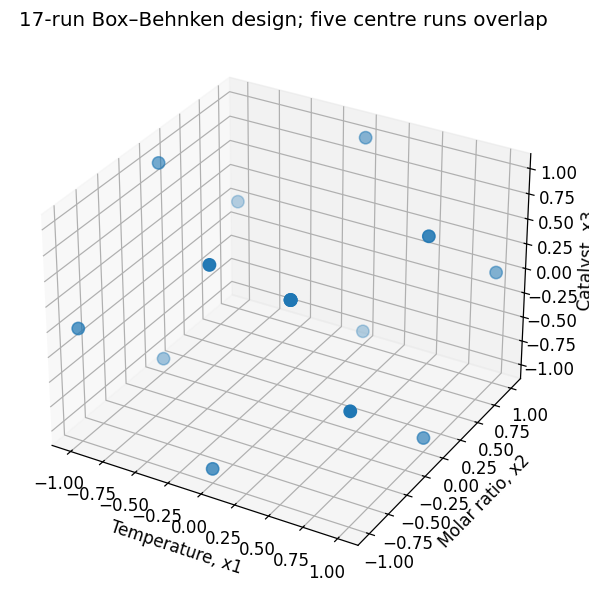

In [7]:
fig = plt.figure(figsize=(8, 5.5))  # Create one three-dimensional plot of the experimental design.
ax = fig.add_subplot(projection='3d')  # Display all three independent factor directions.
ztrain = (train[FEATURES].to_numpy()-CENTRE)/HALF_RANGE  # Plot the design in dimensionless coded coordinates.
ax.scatter(*ztrain.T, s=65)  # Show the design points; five centre observations overlap.
ax.set(xlabel='Temperature, x1', ylabel='Molar ratio, x2', zlabel='Catalyst, x3', title='17-run Box–Behnken design; five centre runs overlap')  # Explain the plot geometry and repeated centre.
save_plot(fig, '01_experimental_design')  # Preserve the first teaching figure.

**Interpretation.** This design does not occupy every corner of the three-input cube. Predictions at unobserved corner combinations must still be checked.

## 3. Specify and fit the response surface
RSM fixes the polynomial family before fitting: four coefficients for a linear model and ten for a full three-input quadratic. Coding changes units and numerical conditioning, not the underlying interaction physics.

In [8]:
def coded(x):  # Express physical inputs relative to the fixed design centre and half-range.
    return (np.atleast_2d(x) - CENTRE) / HALF_RANGE  # Map low and high factor levels to minus and plus one.

def design_matrix(x, degree=2):  # Generate a preselected polynomial structure for RSM.
    poly = PolynomialFeatures(degree=degree, include_bias=True)  # Include an intercept and every term up to the requested degree.
    matrix = poly.fit_transform(coded(x))  # Build polynomial features without using any response data.
    names = poly.get_feature_names_out([f'x{i+1}' for i in range(len(CENTRE))])  # Label the main, squared and interaction terms.
    return pd.DataFrame(matrix, columns=names)  # Preserve interpretable coefficient names in the regression output.

def lack_of_fit(model, x, y):  # Separate within-setting noise from possible inadequacy of the polynomial.
    _, groups = np.unique(np.asarray(x), axis=0, return_inverse=True)  # Identify replicated input conditions.
    pure_sse = sum(np.sum((y[groups == g] - y[groups == g].mean())**2) for g in np.unique(groups))  # Measure variation among repeat observations.
    pure_df = len(y) - len(np.unique(groups))  # Count the pure-error degrees of freedom.
    lof_df = int(model.df_resid) - pure_df  # Allocate remaining residual degrees of freedom to lack of fit.
    lof_sse = max(float(np.sum(model.resid**2)) - pure_sse, 0.0)  # Remove measured repeatability from the residual sum of squares.
    f_stat = (lof_sse/lof_df) / (pure_sse/pure_df)  # Compare lack-of-fit variance with the repeatability estimate.
    p_value = stats.f.sf(f_stat, lof_df, pure_df)  # Evaluate the lack-of-fit upper-tail probability.
    return pd.DataFrame({'source': ['Lack of fit', 'Pure error'], 'sum_squares': [lof_sse, pure_sse], 'df': [lof_df, pure_df], 'F': [f_stat, np.nan], 'p_value': [p_value, np.nan]})  # Present the diagnostic in a compact table.

**Method.** Least squares estimates coefficients inside the chosen family. The lack-of-fit calculation compares residual variation with noise estimated from replicate experiments.

In [9]:
ytrain = train['yield_observed_pct'].to_numpy()  # Fit only the noisy training response.
models = {d: sm.OLS(ytrain, design_matrix(train[FEATURES], d)).fit() for d in [1, 2]}  # Fit both predefined polynomial structures.
validation_scores = pd.DataFrame([{'degree': d, 'coefficients': len(m.params), **metrics(validation['yield_observed_pct'], m.predict(design_matrix(validation[FEATURES], d)))} for d, m in models.items()])  # Evaluate candidate models on validation data only.
selected_degree = int(validation_scores.loc[validation_scores['RMSE'].idxmin(), 'degree'])  # Select the smaller validation error before opening the test results.
model = models[selected_degree]  # Freeze the chosen model for subsequent evaluation.
display(validation_scores.round(4))  # Show the evidence behind model selection.
print('Selected degree:', selected_degree)  # State which model will make the final predictions.
validation_scores.to_csv(RESULTS/'validation_comparison.csv', index=False)  # Save the model-selection record.

,degree,coefficients,RMSE,MAE,R_squared
0,1,4,3.5676,3.2577,0.4832
1,2,10,0.8154,0.6723,0.9730


Selected degree: 2


**Interpretation.** A smaller training error is not sufficient evidence for adding terms. Compare held-out validation performance with model size.

In [10]:
quadratic = models[2]  # Retain the full quadratic for coefficient interpretation regardless of the selection outcome.
ci = quadratic.conf_int(alpha=0.05)  # Calculate Student-t coefficient intervals under the OLS assumptions.
coefficients = pd.DataFrame({'estimate': quadratic.params, 'standard_error': quadratic.bse, 'lower_95': ci[0], 'upper_95': ci[1], 'p_value': quadratic.pvalues})  # Label all fitted terms and their uncertainty.
display(coefficients.round(4))  # Show the coefficients in coded coordinates.
display(lack_of_fit(quadratic, train[FEATURES], ytrain).round(4))  # Check whether remaining variation exceeds replicate noise.
coefficients.to_csv(RESULTS/'quadratic_coefficients.csv')  # Preserve the equation coefficients and their units.
print('Y_hat = '+' + '.join(f'({value:.4f})*{term}' for term, value in quadratic.params.items()))  # Display the fitted equation explicitly.

,estimate,standard_error,lower_95,upper_95,p_value
1,87.9212,0.4513,86.8541,88.9884,0.0000
x1,3.8450,0.3568,3.0013,4.6886,0.0000
x2,2.9114,0.3568,2.0677,3.7550,0.0001
x3,1.7976,0.3568,0.9540,2.6413,0.0015
x1^2,-5.2440,0.4918,-6.4069,-4.0810,0.0000
x1 x2,1.4711,0.5046,0.2779,2.6642,0.0225
x1 x3,-1.3064,0.5046,-2.4995,-0.1132,0.0360
x2^2,-3.2809,0.4918,-4.4438,-2.1179,0.0003
x2 x3,0.8939,0.5046,-0.2993,2.0870,0.1198
x3^2,-2.9599,0.4918,-4.1228,-1.7970,0.0005


,source,sum_squares,df,F,p_value
0,Lack of fit,5.6359,3,5.0342,0.0762
1,Pure error,1.4927,4,NaN,NaN


Y_hat = (87.9212)*1 + (3.8450)*x1 + (2.9114)*x2 + (1.7976)*x3 + (-5.2440)*x1^2 + (1.4711)*x1 x2 + (-1.3064)*x1 x3 + (-3.2809)*x2^2 + (0.8939)*x2 x3 + (-2.9599)*x3^2


**Caution.** A non-significant lack-of-fit result is not proof of adequacy; centre replicates give few pure-error degrees of freedom. Coefficient p-values are not a mechanistic importance ranking.

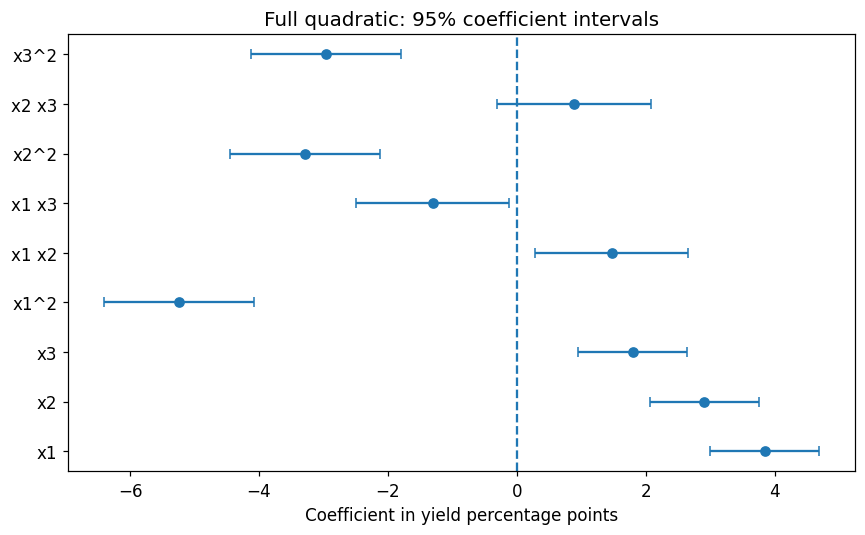

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))  # Create a readable coefficient-interval figure.
shown = coefficients.iloc[1:]  # Omit the large intercept so the effects remain visible.
errors = np.vstack((shown['estimate']-shown['lower_95'], shown['upper_95']-shown['estimate']))  # Use the exact fitted Student-t intervals from the table.
ax.errorbar(shown['estimate'], np.arange(len(shown)), xerr=errors, fmt='o', capsize=3)  # Compare positive, negative and uncertain effects.
ax.set_yticks(np.arange(len(shown)), labels=shown.index)  # Name the main, squared and interaction terms.
ax.axvline(0, linestyle='--')  # Mark the no-effect reference for an individual coefficient.
ax.set(xlabel='Coefficient in yield percentage points', title='Full quadratic: 95% coefficient intervals')  # State the coefficient scale.
save_plot(fig, '02_coefficients')  # Save the coefficient interpretation figure.

**Interpretation.** The local temperature effect contains its main term, its squared term and its interactions. It cannot be read from the temperature main-effect coefficient alone.

## 4. Evaluate independent test observations
The selected model is now fixed. Report errors against noisy observations and, separately, against the synthetic noise-free response. The second quantity is available because this is a controlled teaching experiment.

,reference,RMSE,MAE,R_squared
0,Noisy observations,1.1832,0.9600,0.9085
1,Noise-free truth,0.3692,0.2747,0.9903


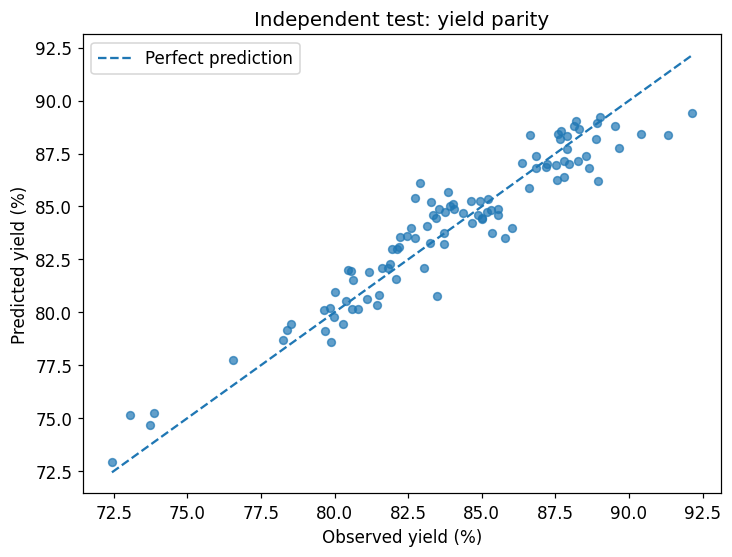

In [12]:
prediction = np.asarray(model.predict(design_matrix(test[FEATURES], selected_degree)))  # Predict the independent test inputs without refitting.
test_metrics = pd.DataFrame([{'reference': 'Noisy observations', **metrics(test['yield_observed_pct'], prediction)}, {'reference': 'Noise-free truth', **metrics(test['yield_true_pct'], prediction)}])  # Separate observation error from surrogate approximation error.
display(test_metrics.round(4))  # Compare the two distinct evaluation targets.
test_results = test.assign(yield_predicted_pct=prediction, residual_pct=prediction-test['yield_observed_pct'])  # Retain individual predictions and their errors.
test_metrics.to_csv(RESULTS/'test_metrics.csv', index=False)  # Save the held-out test metrics.
test_results.to_csv(RESULTS/'test_predictions.csv', index=False)  # Save row-level predictions for checking.
parity(test['yield_observed_pct'], prediction, 'Independent test: yield parity', 'yield (%)', '03_test_parity')  # Display agreement with new noisy measurements.

**Interpretation.** Error relative to the true mean surface can be smaller than the one-percentage-point observation scatter. Error relative to new observations contains both sources.

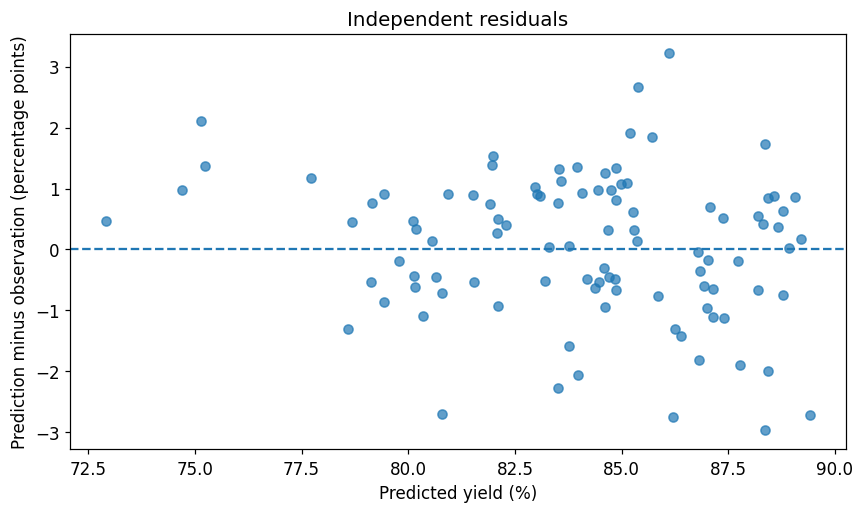

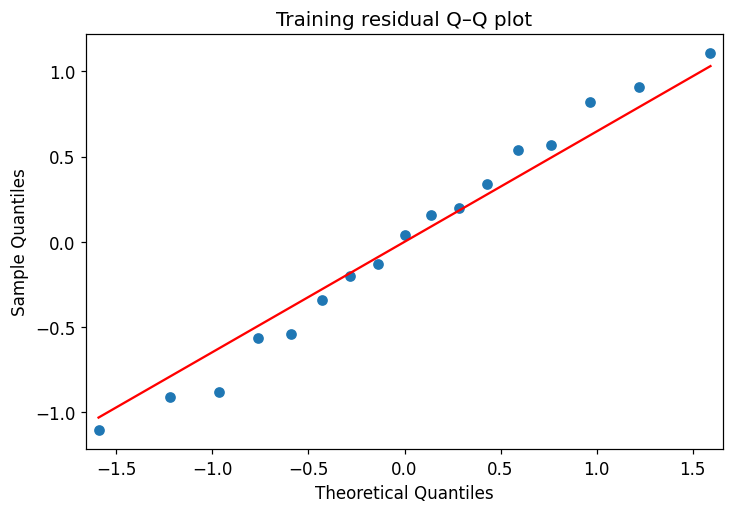

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.8))  # Create one residual diagnostic panel.
ax.scatter(prediction, test_results['residual_pct'], alpha=0.7)  # Look for response-dependent patterns in the independent errors.
ax.axhline(0, linestyle='--')  # Identify the unbiased-error reference.
ax.set(xlabel='Predicted yield (%)', ylabel='Prediction minus observation (percentage points)', title='Independent residuals')  # State the error convention explicitly.
save_plot(fig, '04_residuals')  # Save the test diagnostic.
fig, ax = plt.subplots(figsize=(6.8, 4.8))  # Create a separate normal-probability diagnostic.
sm.qqplot(quadratic.resid, line='s', ax=ax)  # Compare training residual quantiles with a normal reference.
ax.set_title('Training residual Q–Q plot')  # Identify the residual set being inspected.
save_plot(fig, '05_qq')  # Save this diagnostic separately rather than creating cramped subplots.

**Interpretation.** Residual curvature suggests missing response structure. A small sample and a visually straight Q–Q plot cannot establish a correct error distribution or a valid chemical mechanism.

## 5. Visualise the response and uncertainty
Hold catalyst loading at its centre. A two-input slice reveals shape but does not describe all possible three-input combinations.

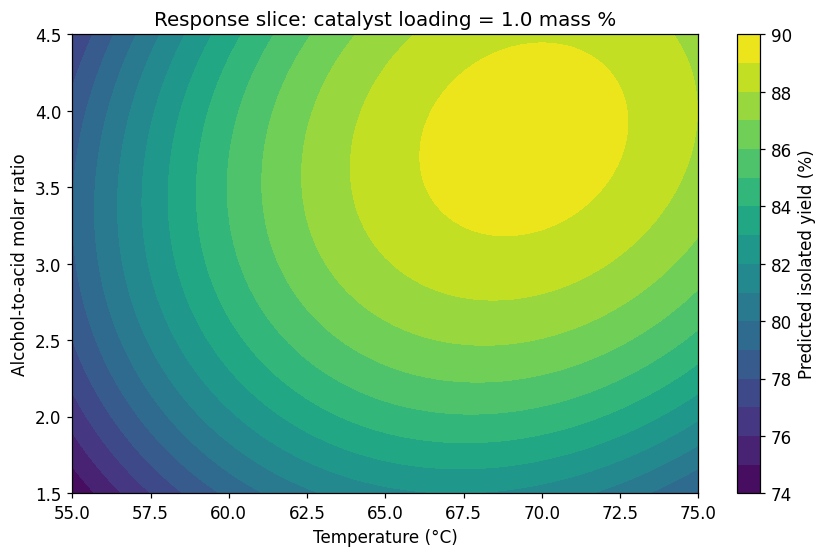

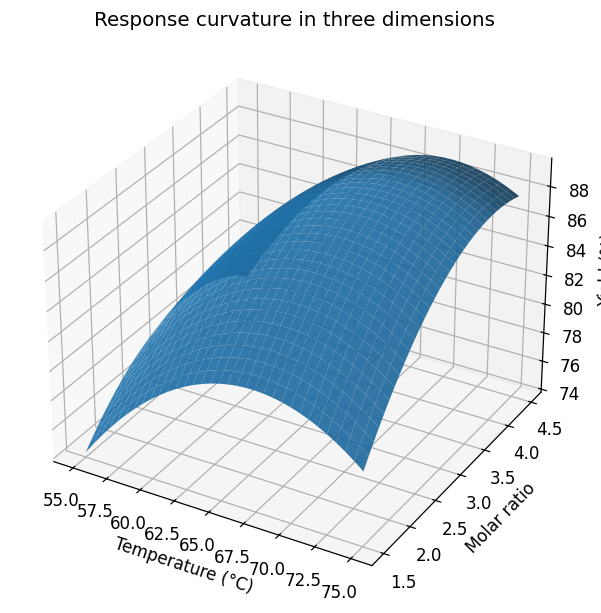

In [14]:
tg, mg = np.meshgrid(np.linspace(55, 75, 65), np.linspace(1.5, 4.5, 65))  # Create a regular temperature-ratio grid for display.
xgrid = np.column_stack((tg.ravel(), mg.ravel(), np.ones(tg.size)))  # Keep catalyst loading fixed at 1.0 mass per cent.
surface = np.asarray(model.predict(design_matrix(xgrid, selected_degree))).reshape(tg.shape)  # Evaluate the selected fitted surface.
fig, ax = plt.subplots(figsize=(8, 5.2))  # Create a contour plot with room for a scale legend.
contour = ax.contourf(tg, mg, surface, levels=18)  # Visualise the predicted yield using the default colour map.
fig.colorbar(contour, ax=ax, label='Predicted isolated yield (%)')  # Show the response units.
ax.set(xlabel='Temperature (°C)', ylabel='Alcohol-to-acid molar ratio', title='Response slice: catalyst loading = 1.0 mass %')  # State the fixed third input.
save_plot(fig, '06_contour')  # Save the quantitative response-surface view.
fig = plt.figure(figsize=(8.2, 5.7))  # Create a separate three-dimensional visualisation.
ax = fig.add_subplot(projection='3d')  # Use yield as the vertical coordinate.
ax.plot_surface(tg, mg, surface, alpha=0.9)  # Display the same response slice in perspective.
ax.set(xlabel='Temperature (°C)', ylabel='Molar ratio', zlabel='Yield (%)', title='Response curvature in three dimensions')  # Label the full surface geometry.
save_plot(fig, '07_surface')  # Save the complementary geometric view.

**Interpretation.** Use the contour plot for numerical reading and the 3D surface for geometric intuition. Both use the same fitted model and the same fixed catalyst loading.

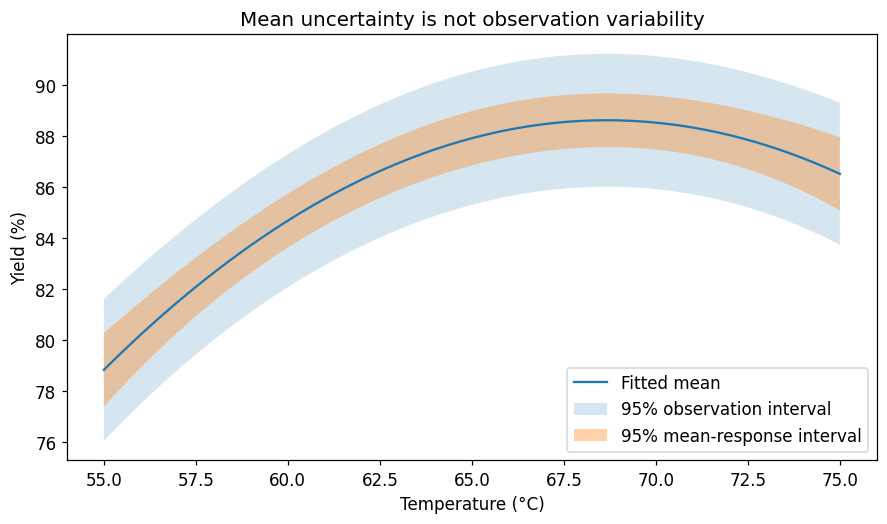

In [15]:
xline = np.column_stack((np.linspace(55, 75, 100), np.full(100, 3.0), np.ones(100)))  # Vary temperature with the other inputs held at their centres.
intervals = model.get_prediction(design_matrix(xline, selected_degree)).summary_frame(alpha=0.05)  # Obtain both mean-response and new-observation intervals.
fig, ax = plt.subplots(figsize=(8.2, 4.9))  # Create one uncertainty plot.
ax.plot(xline[:, 0], intervals['mean'], label='Fitted mean')  # Show the expected yield along this slice.
ax.fill_between(xline[:, 0], intervals['obs_ci_lower'], intervals['obs_ci_upper'], alpha=0.18, label='95% observation interval')  # Include measurement scatter and coefficient uncertainty.
ax.fill_between(xline[:, 0], intervals['mean_ci_lower'], intervals['mean_ci_upper'], alpha=0.35, label='95% mean-response interval')  # Show uncertainty in the mean response alone.
ax.set(xlabel='Temperature (°C)', ylabel='Yield (%)', title='Mean uncertainty is not observation variability')  # Distinguish the two interval meanings.
ax.legend()  # Identify the overlapping uncertainty bands.
save_plot(fig, '08_uncertainty')  # Preserve the interval interpretation figure.

**Interpretation.** The observation interval is wider because it includes a new measurement error. These intervals assume the regression family and noise model are adequate; they do not cover unknown out-of-domain physics.

## 6. Recommend an operating point and verify it
Optimise the frozen surrogate inside the stated input bounds. The noise-free optimum is an instructor benchmark, not a model-selection criterion.

In [16]:
def objective(z):  # Convert maximising yield into the minimisation convention used by SciPy.
    x = CENTRE+np.asarray(z)*HALF_RANGE  # Recover physical operating conditions from a coded candidate.
    return -float(np.asarray(model.predict(design_matrix(x, selected_degree)))[0])  # Minimise negative predicted yield.
starts = [np.zeros(3)]+[np.asarray(z) for z in product((-0.7, 0.7), repeat=3)]  # Use several initial guesses rather than trusting one optimiser start.
solutions = [minimize(objective, z, method='L-BFGS-B', bounds=[(-1, 1)]*3) for z in starts]  # Search inside the allowed operating box.
valid = [r for r in solutions if r.success]  # Exclude runs whose optimiser did not converge.
if not valid:  # Do not report an unverified numerical optimum.
    raise RuntimeError('No optimiser start converged; inspect the regression and bounds.')  # Stop with an informative failure message.
best = min(valid, key=lambda r: r.fun)  # Retain the best converged surrogate solution.
xopt = CENTRE+best.x*HALF_RANGE  # Convert the recommendation into physical units.
oracle = minimize(lambda z: -truth(CENTRE+z*HALF_RANGE)[0], np.zeros(3), bounds=[(-1, 1)]*3)  # Obtain an independent synthetic-truth benchmark.
xoracle = CENTRE+oracle.x*HALF_RANGE  # Recover the noise-free optimum in physical units.
recommendations = pd.DataFrame([CENTRE, xopt, xoracle], columns=FEATURES, index=['Centre baseline', 'Surrogate recommendation', 'Noise-free oracle'])  # Compare the three relevant decisions.
recommendations['predicted_yield_pct'] = np.asarray(model.predict(design_matrix(recommendations[FEATURES], selected_degree)))  # Apply the same learned model to each decision.
recommendations['true_yield_pct'] = truth(recommendations[FEATURES])  # Verify the decisions against the teaching process.
display(recommendations.round(4))  # Show operating conditions and achieved responses together.
recommendations.to_csv(RESULTS/'optimisation.csv')  # Save the operating recommendation and audit.

,temperature_C,alcohol_acid_molar_ratio,catalyst_mass_percent,predicted_yield_pct,true_yield_pct
Centre baseline,65.0000,3.0000,1.0000,87.9212,88.0000
Surrogate recommendation,69.1008,3.8648,1.1501,89.8187,89.9908
Noise-free oracle,69.5968,3.7923,1.1532,89.7938,90.0181


**Interpretation.** The noise-free reference is about 69.60 °C, ratio 3.79 and catalyst loading 1.153 mass %, yielding 90.02%. A noisy-data recommendation need not reproduce these digits. Numerical precision is not experimental certainty.

In [17]:
confirmation_rng = np.random.default_rng(SEED+1001)  # Create fresh observation noise independent of fitting and selection.
confirmation = truth(xopt)[0]+confirmation_rng.normal(0, NOISE_SD, 6)  # Simulate six new confirmation experiments at the recommended point.
confirmation_table = pd.DataFrame({'run': np.arange(1, 7), 'observed_yield_pct': confirmation})  # Label every independent confirmation observation.
display(confirmation_table.round(3))  # Report all six measurements instead of selecting favourable runs.
print(f'Confirmation mean: {confirmation.mean():.3f}%; sample SD: {confirmation.std(ddof=1):.3f} percentage points.')  # Summarise the independent confirmation performance.
print(f'Noise-free decision regret: {truth(xoracle)[0]-truth(xopt)[0]:.4f} percentage points.')  # Measure the loss relative to the constructed ideal optimum.
confirmation_table.to_csv(RESULTS/'confirmation_runs.csv', index=False)  # Preserve the fresh simulated confirmation data.

,run,observed_yield_pct
0,1,92.665
1,2,90.191
2,3,88.977
3,4,88.231
4,5,90.065
5,6,91.190


Confirmation mean: 90.220%; sample SD: 1.578 percentage points.
Noise-free decision regret: 0.0273 percentage points.


**Engineering takeaway.** The objective is a reliable operating recommendation, not a perfect-looking training fit. Independent confirmation and decision regret test whether the model actually helps.

## 7. Exercises and discussion
**A · Noise:** double `NOISE_SD`, rerun from the beginning and explain how the recommendation changes. Do not cherry-pick a random seed.

**B · Structure:** force a linear model and compare its optimum. Explain why a non-constant linear objective over a box generally selects a boundary.

**C · Interaction:** derive $\partial Y/\partial x_1=4-10x_1+2x_2-1.5x_3$. Explain why temperature has no single effect independent of operating conditions.

<details><summary><b>Instructor interpretation</b></summary>
Higher noise increases coefficient uncertainty and can move an optimum. The linear family cannot reproduce an interior curved maximum. Interactions make the derivative depend on the other inputs. Non-significant lack of fit is not proof of a mechanism, and confirmation observations should be independent of the fitted design.
</details>

## Export your results
All figures, generated observations, model coefficients and prediction tables are saved in the case-specific results folder. Download the archive before disconnecting a temporary runtime. Use **File → Download → Download .ipynb** to retain your own comments and outputs.

In [18]:
archive = shutil.make_archive(str(RESULTS) + '_results', 'zip', RESULTS)  # Bundle this run's tables and figures into one archive.
display(FileLink(archive))  # Display a file link in notebook interfaces that support local downloads.
DOWNLOAD_RESULTS = False  # Set this switch to True to start a Colab browser download.
if DOWNLOAD_RESULTS:  # Avoid an unsolicited download during normal Run all execution.
    try:  # Use Colab's helper only in an environment where it exists.
        from google.colab import files  # Load Google's browser-download interface.
        files.download(archive)  # Copy the result archive to the learner's computer.
    except ImportError:  # Keep the same notebook usable in standard Jupyter.
        print('Use the link above or the notebook file browser.')  # Explain the non-Colab download route.
print('Core workflow finished: all displayed core results were calculated in this run.')  # Mark successful completion of the lesson.

/mnt/data/Colab_Teaching_Notebooks/results_01_rsm_esterification_results.zip

Core workflow finished: all displayed core results were calculated in this run.


**Save your work.** Downloading the archive does not itself save edits to the notebook. Save both the `.ipynb` and the results archive.

## Sources and scope
All numerical chemical parameters and synthetic observations are teaching assumptions. The sources support the modelling concepts, not those invented parameter values.

- [Google Colab FAQ](https://research.google.com/colaboratory/faq.html)
- [NIST: response surface designs](https://www.itl.nist.gov/div898/handbook/pri/section3/pri336.htm)
- [statsmodels: ordinary least squares](https://www.statsmodels.org/stable/examples/notebooks/generated/ols.html)
- [SciPy: bounded nonlinear least squares](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.least_squares.html)
- [NIST: Box–Behnken designs](https://www.itl.nist.gov/div898/handbook/pri/section3/pri3362.htm)
- [statsmodels: prediction intervals](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.get_prediction.html)


**Verification boundary.** The supplied core workflow was executed in a clean local Python kernel and its outputs are saved. This is not a claim of execution in Google's hosted runtime. Any optional PySR section is disabled by default and excluded from the core execution check.